# Results analysis: PEFT experiments

Reads everything under `outputs/peft/<experiment>/<language>_<condition>/` and helps you compare runs.

**How to use it:** change fine-tuning settings in a YAML config, train with `scripts/train_peft.py`, then re-run this notebook (Kernel > Restart & Run All). Every new run appears automatically.

**Dev set only.** This notebook reads `dev_metrics.json` and `dev_predictions_*.jsonl`. Use the test set only for the final reported numbers.

Sections: 1. load runs, 2. compare runs and hyperparameters, 3. condition x language matrix, 4. per-emotion F1 across runs, 5. deep dive into one run (support vs predictions, confusion matrix, error examples).

## 1. Setup and loading

In [23]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from sklearn.metrics import multilabel_confusion_matrix

from llm_project.peft_evaluation import EMOTIONS, labels_to_binary, parse_prediction

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RUNS_DIR = ROOT / "outputs" / "peft"  # change if `output.root_dir` in your YAML differs

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)

In [24]:
def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}


def read_jsonl(path: Path) -> list[dict]:
    rows = []
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                rows.append(json.loads(line))
    return rows


def emotion_f1(metrics: dict, emotion: str):
    """Works for the new format (per_emotion) and the older one (per_emotion_f1)."""
    if "per_emotion" in metrics:
        return metrics["per_emotion"][emotion]["f1"]
    return metrics.get("per_emotion_f1", {}).get(emotion, np.nan)


def load_runs(runs_dir: Path) -> pd.DataFrame:
    """One row per (run, evaluation language)."""
    rows = []
    for metrics_path in sorted(runs_dir.glob("*/*/dev_metrics.json")):
        run_dir = metrics_path.parent
        language, _, condition = run_dir.name.partition("_")  # e.g. sv_bilingual

        cfg = {}
        if (run_dir / "config_used.yaml").exists():
            cfg = yaml.safe_load((run_dir / "config_used.yaml").read_text()) or {}
        peft, train = cfg.get("peft", {}), cfg.get("training", {})
        cost = read_json(run_dir / "training_cost.json")

        for eval_language, m in read_json(metrics_path).items():
            if eval_language.startswith("_"):
                continue
            rows.append(
                {
                    "experiment": run_dir.parent.name,
                    "language": language,
                    "condition": condition,
                    "eval_language": eval_language,
                    "micro_f1": m.get("micro_f1"),
                    # older runs used a different Jaccard, so they show NaN here on purpose
                    "sample_jaccard": m.get("sample_jaccard"),
                    "macro_f1": m.get("macro_f1"),
                    "precision": m.get("precision_micro"),
                    "recall": m.get("recall_micro"),
                    "hamming_loss": m.get("hamming_loss"),
                    "malformed": m.get("malformed_output_rate"),
                    "model": cfg.get("model", {}).get("name"),
                    "rank": peft.get("rank"),
                    "alpha": peft.get("alpha"),
                    "dropout": peft.get("dropout"),
                    "lr": train.get("learning_rate"),
                    "epochs": train.get("epochs"),
                    "batch": train.get("batch_size"),
                    "train_min": (
                        round(cost["train_runtime_seconds"] / 60, 1)
                        if "train_runtime_seconds" in cost
                        else None
                    ),
                    "peak_gpu_mb": cost.get("peak_gpu_memory_mb"),
                    "f1_by_emotion": {e: emotion_f1(m, e) for e in EMOTIONS},
                }
            )
    return pd.DataFrame(rows)


runs = load_runs(RUNS_DIR)
if runs.empty:
    raise FileNotFoundError(f"No dev_metrics.json found under {RUNS_DIR}")
print(f"{runs['experiment'].nunique()} experiments, {len(runs)} (run, evaluation language) rows")

4 experiments, 18 (run, evaluation language) rows


## 2. Compare runs and hyperparameters

Sorted by micro-F1 within each evaluation language. Columns after `malformed` are the settings, so you can see which change helped. Older runs lack `sample_jaccard`, `malformed`, and cost columns (shown as NaN).

In [25]:
table_cols = [
    "experiment", "condition", "eval_language",
    "micro_f1", "sample_jaccard", "macro_f1", "hamming_loss", "malformed",
    "rank", "alpha", "lr", "epochs", "batch", "train_min",
]
view = (
    runs[table_cols]
    .sort_values(["eval_language", "micro_f1"], ascending=[True, False])
    .reset_index(drop=True)
)
metric_cols = ["micro_f1", "sample_jaccard", "macro_f1", "hamming_loss", "malformed"]
view[metric_cols] = view[metric_cols].round(3)  # round metrics only, so lr like 3e-4 stays visible
display(view)

,experiment,condition,eval_language,micro_f1,sample_jaccard,macro_f1,hamming_loss,malformed,rank,alpha,lr,epochs,batch,train_min
0,mt0_base_qdora_r64,bilingual,en,0.406,0.345,0.383,0.205,0.0,64,128,0.0003,10,16,21.1
1,mt0_base_v2,bilingual,en,0.403,NaN,0.381,0.209,NaN,64,128,0.0003,10,16,NaN
2,mt0_base_v2,english,en,0.400,NaN,0.367,0.202,NaN,64,128,0.0003,10,16,NaN
3,mt0_base,bilingual,en,0.397,NaN,0.360,0.200,NaN,32,64,0.0003,10,16,NaN
4,mt0_base_v3_epochs15,bilingual,en,0.387,0.329,0.371,0.216,0.0,64,128,0.0003,15,16,15.1
5,mt0_base_v2,mixed,en,0.386,NaN,0.348,0.213,NaN,64,128,0.0003,10,16,NaN
6,mt0_base_v2,target,en,0.383,NaN,0.330,0.211,NaN,64,128,0.0003,10,16,NaN
7,mt0_base,english,en,0.353,NaN,0.272,0.200,NaN,32,64,0.0003,10,16,NaN
8,mt0_base,target,en,0.343,NaN,0.221,0.200,NaN,32,64,0.0003,10,16,NaN
9,mt0_base_v2,bilingual,sv,0.358,NaN,0.334,0.223,NaN,64,128,0.0003,10,16,NaN


## 3. Run x evaluation-language matrix

Pick a metric. Rows are runs, columns are the language the model was evaluated on. This is the cross-lingual view: for an English-only run, the Swedish column shows transfer.

eval_language                               en     sv
experiment           language condition              
mt0_base             sv       bilingual  0.397  0.331
                              english    0.353  0.289
                              target     0.343  0.304
mt0_base_qdora_r64   sv       bilingual  0.406  0.352
mt0_base_v2          sv       bilingual  0.403  0.358
                              english    0.400  0.328
                              mixed      0.386  0.329
                              target     0.383  0.356
mt0_base_v3_epochs15 sv       bilingual  0.387  0.341

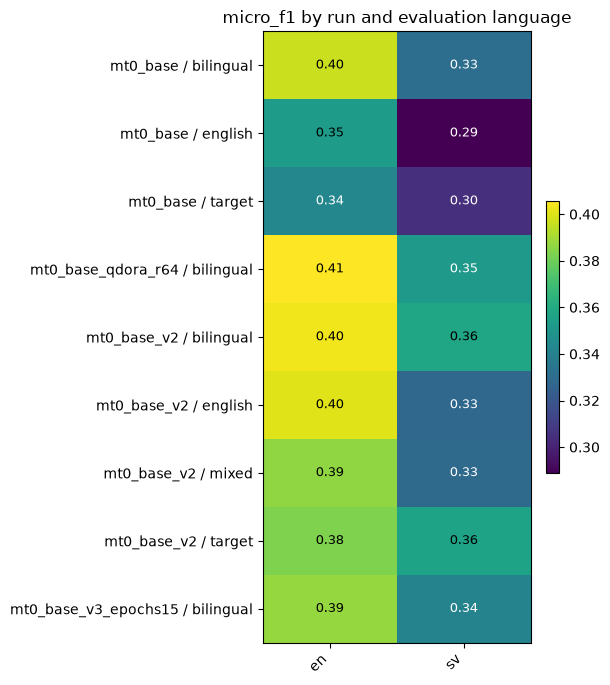

In [26]:
def heatmap(ax, data, xlabels, ylabels, title, fmt="{:.2f}", cmap="viridis", vmin=None, vmax=None):
    data = np.asarray(data, dtype=float)
    lo = np.nanmin(data) if vmin is None else vmin
    hi = np.nanmax(data) if vmax is None else vmax
    im = ax.imshow(data, cmap=cmap, vmin=lo, vmax=hi, aspect="auto")
    ax.set_xticks(range(len(xlabels)), labels=xlabels, rotation=45, ha="right")
    ax.set_yticks(range(len(ylabels)), labels=ylabels)
    ax.set_title(title)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data[i, j]
            if np.isnan(v):
                continue
            share = (v - lo) / (hi - lo) if hi > lo else 0.5
            ax.text(j, i, fmt.format(v), ha="center", va="center",
                    color="white" if share < 0.55 else "black", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046)


METRIC = "micro_f1"  # try "sample_jaccard", "macro_f1", "malformed", "hamming_loss"

matrix = runs.pivot_table(
    index=["experiment", "language", "condition"], columns="eval_language", values=METRIC
)
display(matrix.round(3))

fig, ax = plt.subplots(figsize=(1.6 * len(matrix.columns) + 3, 0.55 * len(matrix) + 2))
heatmap(
    ax, matrix.to_numpy(), list(matrix.columns),
    [f"{e} / {c}" for e, _, c in matrix.index], f"{METRIC} by run and evaluation language",
)
plt.tight_layout()
plt.show()

## 4. Per-emotion F1 across runs

Shows which emotions each run learned. Rows of near-zero on the rare emotions mean the model mostly predicts the common ones.

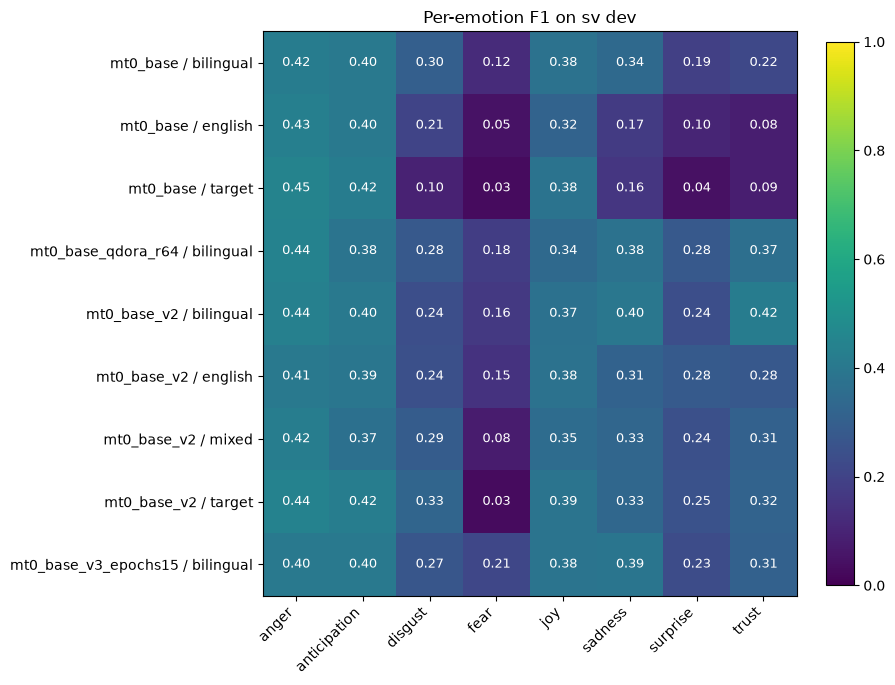

In [27]:
EVAL_LANG = "sv"  # "en" or your target language

subset = runs[runs["eval_language"] == EVAL_LANG].reset_index(drop=True)
per_emotion = np.array([[r[e] for e in EMOTIONS] for r in subset["f1_by_emotion"]], dtype=float)

fig, ax = plt.subplots(figsize=(9, 0.55 * len(subset) + 2))
heatmap(
    ax, per_emotion, EMOTIONS,
    [f"{e} / {c}" for e, c in zip(subset["experiment"], subset["condition"], strict=True)],
    f"Per-emotion F1 on {EVAL_LANG} dev", vmin=0, vmax=1,
)
plt.tight_layout()
plt.show()

## 5. Deep dive into one run

Set the three variables below. This reads that run's `dev_predictions_*.jsonl` and re-parses the raw model outputs with your evaluation code.

In [28]:
EXPERIMENT = runs["experiment"].iloc[0]  # or a name such as "mt0_base_v3_epochs15"
RUN = "sv_bilingual"
DEEP_LANG = "sv"  # which dev set: "en" or the target language

run_dir = RUNS_DIR / EXPERIMENT / RUN
preds = pd.DataFrame(read_jsonl(run_dir / f"dev_predictions_{DEEP_LANG}.jsonl"))
if preds.empty:
    raise FileNotFoundError(f"No predictions found in {run_dir}")

gold = [parse_prediction(x)[0] for x in preds["output"]]
parsed = [parse_prediction(x) for x in preds["prediction"]]
pred = [p[0] for p in parsed]

preds["gold"] = gold
preds["pred"] = pred
preds["malformed"] = [p[1] for p in parsed]

y_true = labels_to_binary(gold)
y_pred = labels_to_binary(pred)
print(f"{EXPERIMENT} / {RUN} on {DEEP_LANG}: {len(preds)} examples, "
      f"{preds['malformed'].mean():.1%} malformed")

mt0_base / sv_bilingual on sv: 497 examples, 0.0% malformed


### 5a. Gold labels vs predicted labels per emotion

If the predicted bar is much lower than the gold bar for an emotion, the model under-predicts it.

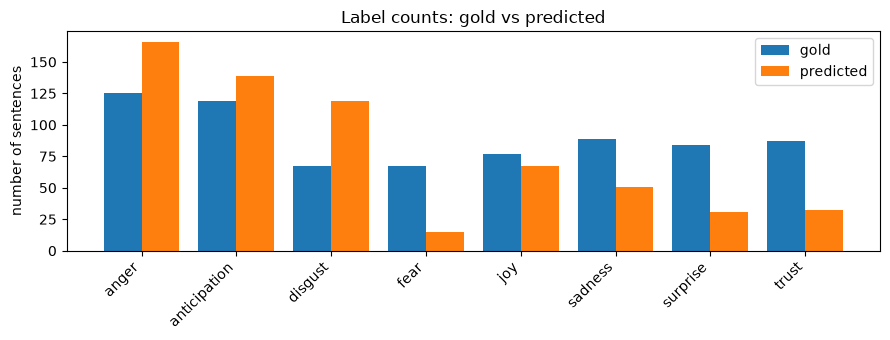

mean labels per sentence, gold:      1.44
mean labels per sentence, predicted: 1.25


In [29]:
x = np.arange(len(EMOTIONS))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(x - 0.2, y_true.sum(axis=0), width=0.4, label="gold")
ax.bar(x + 0.2, y_pred.sum(axis=0), width=0.4, label="predicted")
ax.set_xticks(x, labels=EMOTIONS, rotation=45, ha="right")
ax.set_ylabel("number of sentences")
ax.legend()
ax.set_title("Label counts: gold vs predicted")
plt.tight_layout()
plt.show()

print("mean labels per sentence, gold:     ", round(y_true.sum(axis=1).mean(), 2))
print("mean labels per sentence, predicted:", round(y_pred.sum(axis=1).mean(), 2))

### 5b. Emotion confusion matrix

Multi-label version of a confusion matrix. Cell (i, j) is the share of sentences whose gold labels include emotion i where the model predicted emotion j. The diagonal is per-emotion recall. Off-diagonal cells show which emotion the model says instead. The last column, `none`, is the share where the model predicted no emotion at all. Rows do not sum to 1 because a sentence can carry several labels.

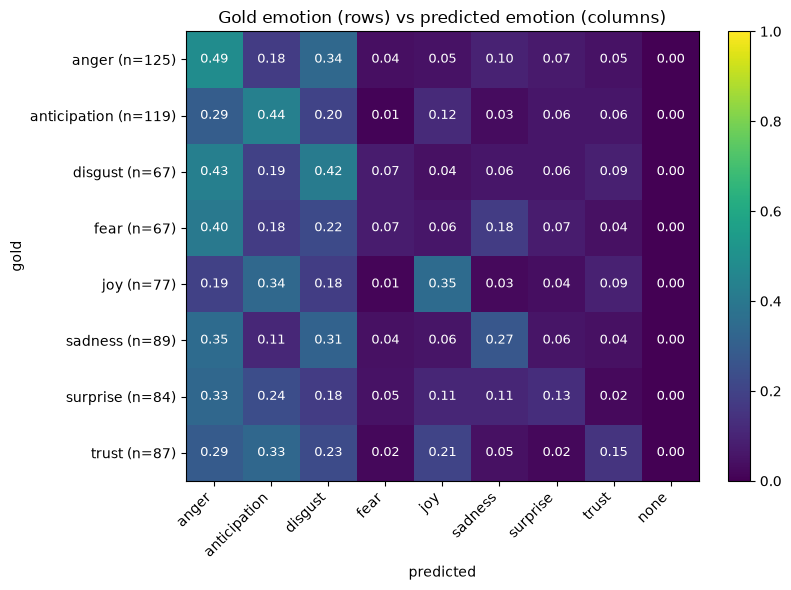

In [30]:
conf = np.zeros((len(EMOTIONS), len(EMOTIONS) + 1))
for t, p in zip(y_true, y_pred, strict=True):
    for i in np.flatnonzero(t):
        conf[i, : len(EMOTIONS)] += p
        conf[i, -1] += int(p.sum() == 0)

support = np.maximum(y_true.sum(axis=0), 1)
conf_share = conf / support[:, None]

fig, ax = plt.subplots(figsize=(8, 6))
heatmap(
    ax, conf_share, [*EMOTIONS, "none"],
    [f"{e} (n={int(s)})" for e, s in zip(EMOTIONS, y_true.sum(axis=0), strict=True)],
    "Gold emotion (rows) vs predicted emotion (columns)", vmin=0, vmax=1,
)
ax.set_xlabel("predicted")
ax.set_ylabel("gold")
plt.tight_layout()
plt.show()

### 5c. Per-emotion TP / FP / FN / TN

In [31]:
mcm = multilabel_confusion_matrix(y_true, y_pred)
display(
    pd.DataFrame(
        {e: {"TP": m[1, 1], "FP": m[0, 1], "FN": m[1, 0], "TN": m[0, 0]}
         for e, m in zip(EMOTIONS, mcm, strict=True)}
    ).T
)

,TP,FP,FN,TN
anger,61,105,64,267
anticipation,52,87,67,291
disgust,28,91,39,339
fear,5,10,62,420
joy,27,40,50,380
sadness,24,27,65,381
surprise,11,20,73,393
trust,13,19,74,391


### 5d. Error examples

For your qualitative analysis. Wrong predictions first, then malformed outputs. Remember that Swedish labels are projected from English, so some errors may come from the projection and not from the model.

In [32]:
wrong = preds[[set(g) != set(p) for g, p in zip(preds["gold"], preds["pred"], strict=True)]]
print(f"{len(wrong)} of {len(preds)} sentences have a wrong label set")
display(wrong[["input", "gold", "pred", "prediction"]].sample(min(15, len(wrong)), random_state=0))

410 of 497 sentences have a wrong label set


,input,gold,pred,prediction
356,"Firman ligger illa till hos banken, om det nu angår dig.",[anger],"[anger, disgust]","[""anger"", ""disgust""]"
85,Smak för dyra saker.,[joy],"[anger, disgust]","[""anger"", ""disgust""]"
313,Jag vet några franska ord.,[trust],[anticipation],"[""anticipation""]"
452,Pappa och hans partner drev ett slags pyramidspel.,"[anger, disgust]",[disgust],"[""disgust""]"
361,Vad bad han dig att berätta?,"[anger, anticipation]",[anger],"[""anger""]"
173,Du ska jobba som hemlig agent. kompis!,[trust],"[anticipation, joy]","[""anticipation"", ""joy""]"
106,Heja Tommy!,[anger],[joy],"[""joy""]"
11,"- Nej, jag vill höra mera.","[anticipation, surprise]",[anger],"[""anger""]"
256,- Som jag har ringt!,"[anger, trust]",[trust],"[""trust""]"
394,Jag hade lagt upp din film på YouTube och visat dem vem geniet är här.,"[anger, anticipation]",[anticipation],"[""anticipation""]"


In [33]:
bad = preds[preds["malformed"]]
print(f"{len(bad)} malformed outputs")
if len(bad):
    display(bad[["input", "prediction"]].head(15))

0 malformed outputs
